# 07 — So sánh các phương pháp phân lớp MNIST

**Mục tiêu:** so sánh Gaussian NB, Softmax, MLP tự cài đặt và Stacking AdaBoost về chất lượng phân lớp, khả năng tổng quát hóa, thời gian huấn luyện/dự đoán, lỗi theo lớp và khả năng giải thích. Đối chiếu sklearn và phần mở rộng CNN/augmentation được trình bày riêng.

**Đầu vào:** kết quả 02–04, 05 → 06 trong `results/`; không tải dữ liệu, không nạp model và không huấn luyện lại. Dùng `metrics_all_splits.csv` cho Gaussian/MLP và `metrics.csv` cho Softmax/stacking, không đọc bảng tổng hợp cũ làm nguồn chính.

**Nguyên tắc:** giữ cấu hình đã chốt ở notebook nguồn; không chọn cấu hình theo test. Báo cáo mọi pipeline chính theo thứ tự cố định. Validation đã dùng tuning nên không phải đánh giá độc lập; kết quả một seed chưa chứng minh ưu thế ổn định.

**Đầu ra:** CSV, PNG 300 dpi, nhận xét Markdown và danh sách đầu ra tại `results/comparison/`. Mỗi phần có mục tiêu, bảng/biểu đồ và nhận xét bằng Markdown. Chạy từ thư mục gốc dự án hoặc `notebooks/`.

**Nhận xét:** trình bày trong các ô Markdown sau bảng/biểu đồ, theo kết quả nguồn hiện tại. Nếu huấn luyện lại và kết quả thay đổi, cần cập nhật số liệu trong các ô nhận xét tương ứng.

## 1. Đọc và chuẩn hóa kết quả
**Mục tiêu:** thống nhất schema mà không thay đổi số liệu đã chạy. Chạy xong các notebook nguồn trước khi chạy phần tổng hợp này.

In [16]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUT = ROOT / 'results' / 'comparison'
OUTPUT.mkdir(parents=True, exist_ok=True)
METHODS = ['Gaussian NB', 'Softmax', 'MLP', 'Stacking AdaBoost']
SPLITS = ['Train', 'Validation', 'Test']
METRICS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
COLORS = dict(zip(METHODS, ['#718096', '#3182ce', '#319795', '#805ad5']))
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
specs = {'Gaussian NB': ('gaussian', 'metrics_all_splits.csv', 'manual', 'confusion_manual_'), 'Softmax': ('softmax', 'metrics.csv', 'Softmax tự viết', 'confusion_'), 'MLP': ('mlp', 'metrics_all_splits.csv', 'manual', 'confusion_manual_'), 'Stacking AdaBoost': ('stacking_adaboost', 'metrics.csv', 'Stacking AdaBoost', 'Stacking_AdaBoost_confusion_')}
tables, figures = ({}, [])

def savefig(name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(OUTPUT / name, dpi=300, bbox_inches='tight')
    figures.append(name)
    plt.show()
    plt.close()
raw, configs, matrices, parts = ({}, {}, {}, [])
for method, (folder, filename, model_name, prefix) in specs.items():
    directory = ROOT / 'results' / folder
    frame = pd.read_csv(directory / filename)
    frame['split'] = frame['split'].str.strip().str.capitalize()
    raw[method] = frame
    configs[method] = json.loads((directory / 'config.json').read_text(encoding='utf-8'))
    table = frame.loc[frame.model == model_name].copy()
    table['method'] = method
    parts.append(table)
    for split in SPLITS:
        cm_frame = pd.read_csv(directory / f'{prefix}{split.lower()}.csv', index_col=0)
        matrices[method, split] = cm_frame.to_numpy(dtype=float)
results = pd.concat(parts, ignore_index=True)
results = results[['method', 'split', *METRICS, 'fit_seconds', 'predict_seconds']]

## 2. Giao thức so sánh
**Mục tiêu:** tóm tắt số mẫu và seed của bốn phương pháp.

Dữ liệu được scale pixel /255, làm phẳng thành 784 đặc trưng và chia phân tầng 50.000 train / 10.000 validation / 10.000 test với seed 42. Notebook này đọc trực tiếp đầu ra đã có của các notebook trước, không huấn luyện hoặc thay đổi cấu hình.

In [17]:
def class_scores(cm):
    tp = np.diag(cm)
    precision = tp / cm.sum(0)
    recall = tp / cm.sum(1)
    f1 = 2 * precision * recall / (precision + recall)
    return (precision, recall, f1)
protocol = pd.DataFrame([{'method': name, 'seed': configs[name]['seed'], **{split: int(matrices[name, split].sum()) for split in SPLITS}} for name in METHODS])
display(protocol)
tables['protocol'] = protocol

,method,seed,Train,Validation,Test
0,Gaussian NB,42,50000,10000,10000
1,Softmax,42,50000,10000,10000
2,MLP,42,50000,10000,10000
3,Stacking AdaBoost,42,50000,10000,10000


Các kết quả nguồn đã được đối chiếu với confusion matrix trong quá trình hoàn thiện. Chỉ số train/validation đã lưu của Gaussian NB, MLP và stacking trùng nhau; Softmax chưa lưu file chỉ số chia tập. Cùng số mẫu và seed chưa đủ để xác nhận danh tính ảnh nếu thay đổi pipeline dữ liệu.

## 3. Cấu hình cuối và phạm vi so sánh
**Mục tiêu:** làm rõ đang so sánh pipeline nào, tránh nhầm MLP tự viết với MLP cơ sở trong stacking. Không chọn lại cấu hình tại notebook này.

In [18]:
g, s, m, e = [configs[name] for name in METHODS]
mlp = m['final_manual']
configuration = pd.DataFrame([
    ['Gaussian NB', f"var_smoothing={g['final_manual_var_smoothing']}", 'Ước lượng thống kê theo lớp', 'Giá trị cuối được giữ từ notebook nguồn'],
    ['Softmax', f"lr={s['learning_rate']}; L2={s['l2']}; batch={s['batch_size']}; epochs={s['epochs']}",
     f"Mini-batch GD; checkpoint epoch {s['best_epoch']}", s.get('selection', '')],
    ['MLP', f"784 → {' → '.join(map(str, mlp['hidden_units']))} → 10; lr={mlp['learning_rate']}; L2={mlp['l2']}; batch={mlp['batch_size']}; epochs={mlp['epochs']}",
     'NumPy; backpropagation ; SGD', m['selection']],
    ['Stacking AdaBoost', f"{e['folds']}-fold OOF; {', '.join(e['model_order'])}; meta: depth={e['max_depth']}, lr={e['learning_rate']}, trees={e['n_estimators']}",
     'Base learners + AdaBoost thư viện; stacking', 'Đọc bộ ba model từ file chọn'],
], columns=['method', 'configuration', 'implementation', 'selection'])
display(configuration)
tables['final_configurations'] = configuration

,method,configuration,implementation,selection
0,Gaussian NB,var_smoothing=0.001,Ước lượng thống kê theo lớp,Giá trị cuối được giữ từ notebook nguồn
1,Softmax,lr=0.5; L2=2e-05; batch=256; epochs=100,Mini-batch GD; checkpoint epoch 58,"Sequential search; validation F1 macro, CE bre..."
2,MLP,784 → 256 → 128 → 64 → 10; lr=0.1; L2=1e-05; b...,NumPy; backpropagation ; SGD,Combine best values from separate validation s...
3,Stacking AdaBoost,"5-fold OOF; SVM, KNN, MLP256_128; meta: depth=...",Base learners + AdaBoost thư viện; stacking,Đọc bộ ba model từ file chọn


**Phạm vi:** so sánh các pipeline đã xây dựng, không phải benchmark có ngân sách tìm kiếm ngang nhau. MLP tự viết ở 04 khác MLP256_128 của bộ ba 05/06; không gộp hai mô hình này. Validation đã dùng chọn cấu hình/checkpoint. OOF chỉ ngăn meta-model thấy dự đoán in-sample khi huấn luyện; không biến validation đã tuning thành tập đánh giá độc lập.

## 4. So sánh chất lượng và chênh lệch giữa các tập
**Mục tiêu:** báo cáo đủ accuracy, precision, recall, F1 macro trên cả ba tập; lượng hóa số lỗi và khoảng cách train–validation. Điểm số lưu dạng tỷ lệ, hậu tố `_pp` là điểm phần trăm.

,method,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,Gaussian NB,Train,0.76832,0.79230,0.76344,0.76409,0.41044,5.52608
1,Gaussian NB,Validation,0.76350,0.79085,0.75874,0.76000,0.41044,1.11223
2,Gaussian NB,Test,0.77530,0.80187,0.77068,0.77161,0.41044,1.10302
3,Softmax,Train,0.93330,0.93253,0.93232,0.93232,11.15064,0.02319
4,Softmax,Validation,0.92280,0.92196,0.92187,0.92180,11.15064,0.00364
5,Softmax,Test,0.92530,0.92440,0.92409,0.92410,11.15064,0.00885
6,MLP,Train,1.00000,1.00000,1.00000,1.00000,1980.53250,0.13343
7,MLP,Validation,0.98300,0.98295,0.98281,0.98286,1980.53250,0.03594
8,MLP,Test,0.98190,0.98185,0.98170,0.98177,1980.53250,0.03481
9,Stacking AdaBoost,Train,0.99998,0.99998,0.99998,0.99998,6513.24132,289.05112


,accuracy,precision_macro,recall_macro,f1_macro,correct,errors
method,,,,,,
Gaussian NB,0.7753,0.80187,0.77068,0.77161,7753,2247
Softmax,0.9253,0.92440,0.92409,0.92410,9253,747
MLP,0.9819,0.98185,0.98170,0.98177,9819,181
Stacking AdaBoost,0.9854,0.98540,0.98534,0.98536,9854,146


split,Train,Validation,Test,train_minus_validation_pp,validation_minus_test_pp
method,,,,,
Gaussian NB,0.7683,0.7635,0.7753,0.482,-1.18
Softmax,0.9333,0.9228,0.9253,1.050,-0.25
MLP,1.0000,0.9830,0.9819,1.700,0.11
Stacking AdaBoost,1.0000,0.9853,0.9854,1.468,-0.01


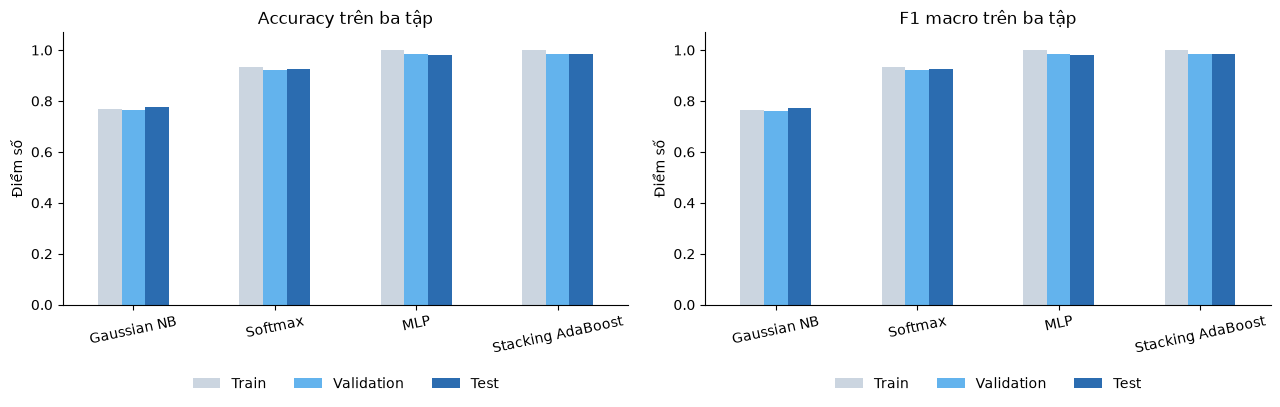

In [19]:
display(results.round(5))
test = results.loc[results.split == 'Test'].set_index('method').loc[METHODS].copy()
test['correct'] = [int(np.trace(matrices[name, 'Test'])) for name in METHODS]
test['errors'] = 10000 - test['correct']
display(test[METRICS + ['correct', 'errors']].round(5))
accuracy = results.pivot(index='method', columns='split', values='accuracy').loc[METHODS, SPLITS]
f1_table = results.pivot(index='method', columns='split', values='f1_macro').loc[METHODS, SPLITS]
gaps = accuracy.copy()
gaps['train_minus_validation_pp'] = 100 * (gaps.Train - gaps.Validation)
gaps['validation_minus_test_pp'] = 100 * (gaps.Validation - gaps.Test)
display(gaps.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, table, title in zip(axes, [accuracy, f1_table], ['Accuracy', 'F1 macro']):
    table.plot.bar(ax=ax, rot=12, ylim=(0, 1.07), color=['#cbd5e0', '#63b3ed', '#2b6cb0'])
    ax.set(xlabel='', ylabel='Điểm số', title=title + ' trên ba tập')
    ax.legend(title='', loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
savefig('scores_by_split.png')
tables.update(metrics_all_splits=results, test_comparison=test.reset_index(), generalization_gaps=gaps.reset_index())

**Nhận xét:** Stacking AdaBoost đạt test accuracy cao nhất trong bốn pipeline (98.54%), với 146 ảnh sai. MLP tự viết có train accuracy 100.00% và validation 98.30%, chênh 1.70 điểm phần trăm. Đây là dấu hiệu chênh lệch khớp train và tổng quát hóa, chưa đủ xác định nguyên nhân. Train của stacking được dự đoán bằng base models refit, không phải điểm OOF độc lập.

## 5. Chi phí và đánh đổi độ chính xác–thời gian
**Mục tiêu:** so sánh thời gian fit cấu hình cuối và dự đoán toàn bộ 10.000 ảnh test. Với stacking, `fit_seconds` gồm tạo OOF, refit base và fit meta cuối; chưa gồm toàn bộ tuning base/meta. Thời gian dự đoán gồm cả base learners và bước gộp.

Không dùng tốc độ của các lượt đo khác nhau như benchmark kiểm soát phần cứng. `ms_per_image_batch_average` chỉ là trung bình một batch lớn, không phải latency xử lý từng yêu cầu. Không tự điền 0 cho thời gian tìm kiếm chưa được lưu.

,accuracy,fit_seconds,predict_seconds,ms_per_image_batch_average,test_images_per_second
method,,,,,
Gaussian NB,0.7753,0.41044,1.10302,0.11030,9.066024e+03
Softmax,0.9253,11.15064,0.00885,0.00089,1.129726e+06
MLP,0.9819,1980.53250,0.03481,0.00348,2.872746e+05
Stacking AdaBoost,0.9854,6513.24132,50.71464,5.07146,1.971817e+02


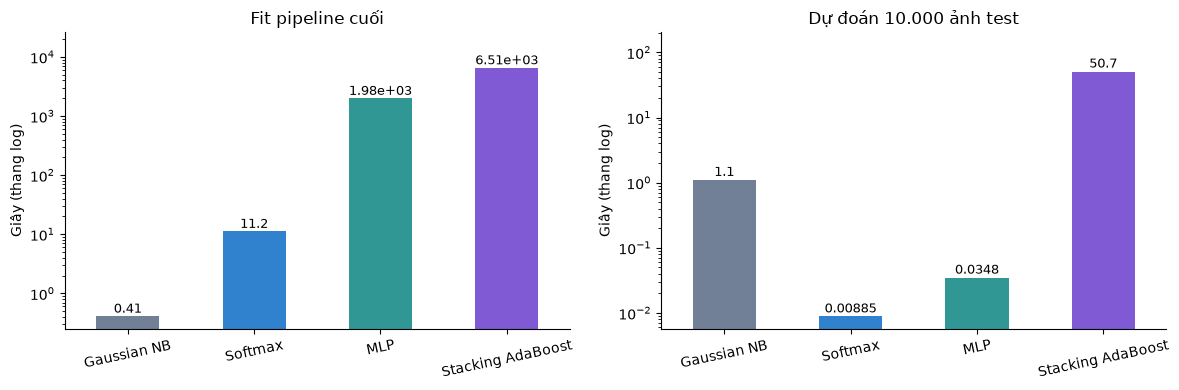

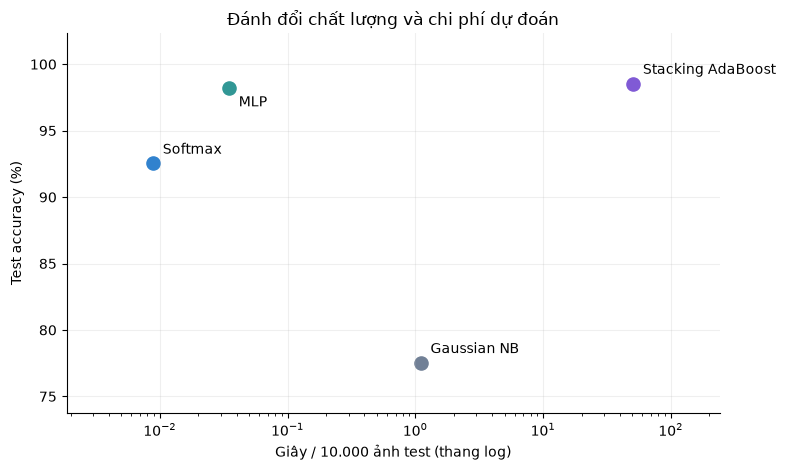

In [20]:
timing = test[['accuracy', 'fit_seconds', 'predict_seconds']].copy()
timing['ms_per_image_batch_average'] = timing.predict_seconds / 10000 * 1000
timing['test_images_per_second'] = 10000 / timing.predict_seconds
display(timing.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(axes, ['fit_seconds', 'predict_seconds'], ['Fit pipeline cuối', 'Dự đoán 10.000 ảnh test']):
    timing[column].plot.bar(ax=ax, rot=12, logy=True, color=[COLORS[x] for x in METHODS])
    ax.set(xlabel='', ylabel='Giây (thang log)', title=title)
    for i, value in enumerate(timing[column]):
        ax.text(i, value * 1.15, f'{value:.3g}', ha='center', fontsize=9)
    ax.set_ylim(top=timing[column].max() * 4)
savefig('timing.png')
fig, ax = plt.subplots(figsize=(8, 4.8))
for name, row in timing.iterrows():
    ax.scatter(row.predict_seconds, row.accuracy * 100, s=90, color=COLORS[name])
    ax.annotate(name, (row.predict_seconds, row.accuracy * 100), xytext=(7, -13 if name == 'MLP' else 7), textcoords='offset points')
ax.set(xscale='log', xlabel='Giây / 10.000 ảnh test (thang log)', ylabel='Test accuracy (%)', title='Đánh đổi chất lượng và chi phí dự đoán')
ax.margins(x=0.18, y=0.18)
ax.grid(alpha=0.2)
savefig('accuracy_vs_prediction_time.png')
tables['timing'] = timing.reset_index()

**Nhận xét:** so với MLP tự viết, stacking tăng 0.35 điểm phần trăm accuracy, nhưng thời gian fit ghi nhận gấp 3.3 lần và dự đoán gấp 1456.9 lần. Các tỷ số mô tả các phép đo đã lưu, chưa tách ảnh hưởng môi trường. Không có mô hình tốt nhất đồng thời cho mọi nhu cầu.

## 6. Confusion matrix và chất lượng theo lớp
**Mục tiêu:** so sánh kiểu lỗi giữa bốn phương pháp, xác định lớp recall thấp và hướng nhầm phổ biến. Ma trận được chuẩn hóa theo hàng (nhãn thật), dùng chung thang màu; CSV vẫn lưu số đếm gốc.

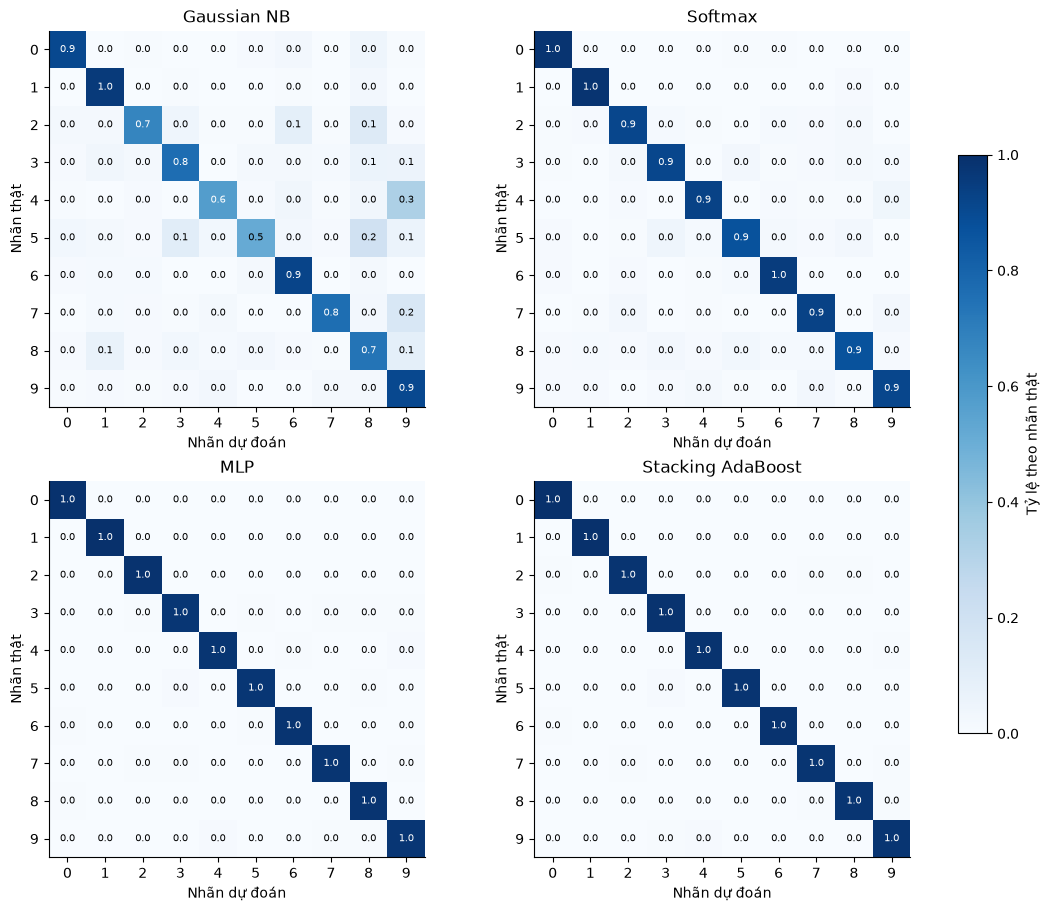

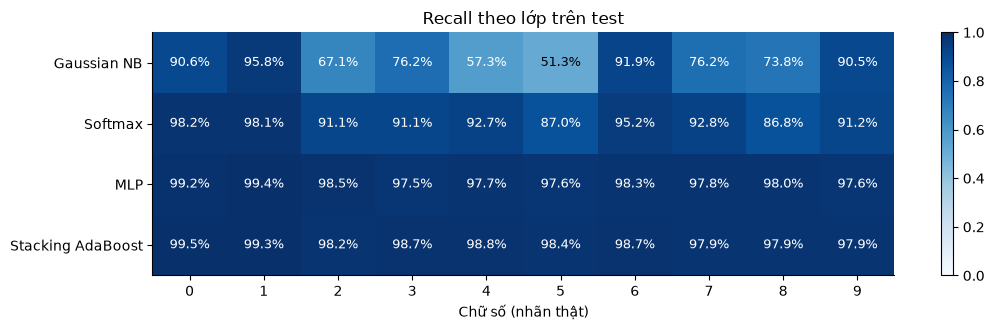

,method,digit,precision,recall,f1,support
5,Gaussian NB,5,0.8450,0.5135,0.6388,892
18,Softmax,8,0.9076,0.8676,0.8871,974
23,MLP,3,0.9811,0.9752,0.9782,1010
37,Stacking AdaBoost,7,0.9824,0.9786,0.9805,1028


,method,true_digit,predicted_digit,count,fraction_of_true_class
0,Gaussian NB,4,9,319,0.3248
1,Gaussian NB,5,8,176,0.1973
2,Gaussian NB,7,9,160,0.1556
3,Softmax,5,3,39,0.0437
4,Softmax,4,9,36,0.0367
5,Softmax,7,9,28,0.0272
6,MLP,4,9,10,0.0102
7,MLP,9,4,8,0.0079
8,MLP,5,3,7,0.0078
9,Stacking AdaBoost,7,9,8,0.0078


In [21]:
class_rows, confusion_rows = ([], [])
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for ax, name in zip(axes.flat, METHODS):
    cm = matrices[name, 'Test']
    normalized = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(normalized, vmin=0, vmax=1, cmap='Blues')
    ax.set(title=name, xlabel='Nhãn dự đoán', ylabel='Nhãn thật', xticks=range(10), yticks=range(10))
    for i in range(10):
        for j in range(10):
            value = normalized[i, j]
            ax.text(j, i, f'{value:.1f}', ha='center', va='center',
                    fontsize=7, color='white' if value > 0.55 else 'black')
    precision, recall, f1 = class_scores(cm)
    for digit in range(10):
        class_rows.append(dict(method=name, digit=digit, precision=precision[digit], recall=recall[digit], f1=f1[digit], support=int(cm[digit].sum())))
    pairs = [(i, j, int(cm[i, j])) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
    for i, j, count in sorted(pairs, key=lambda x: (-x[2], x[0], x[1]))[:3]:
        confusion_rows.append(dict(method=name, true_digit=i, predicted_digit=j, count=count, fraction_of_true_class=count / cm[i].sum()))
fig.colorbar(im, ax=list(axes.flat), shrink=0.7, label='Tỷ lệ theo nhãn thật')
fig.savefig(OUTPUT / 'confusion_matrices_normalized.png', dpi=300, bbox_inches='tight')
figures.append('confusion_matrices_normalized.png')
plt.show()
plt.close()
per_class = pd.DataFrame(class_rows)
recall_table = per_class.pivot(index='method', columns='digit', values='recall').loc[METHODS]
top_confusions = pd.DataFrame(confusion_rows)
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(recall_table, vmin=0, vmax=1, cmap='Blues', aspect='auto')
ax.set(xticks=range(10), yticks=range(4), yticklabels=METHODS, xlabel='Chữ số (nhãn thật)', title='Recall theo lớp trên test')
for i in range(4):
    for j in range(10):
        value = recall_table.iloc[i, j]
        ax.text(j, i, f'{value:.1%}', ha='center', va='center', fontsize=9, color='white' if value > 0.55 else 'black')
fig.colorbar(im, ax=ax)
savefig('recall_by_digit.png')
worst_classes = per_class.loc[per_class.groupby('method', sort=False).recall.idxmin()]
display(worst_classes.round(4))
display(top_confusions.round(4))
tables.update(per_class_test=per_class, top_confusions=top_confusions, weakest_classes=worst_classes)

**Nhận xét:** Gaussian NB: lớp 5 có recall thấp nhất 51.35%; Softmax: lớp 8 có recall thấp nhất 86.76%; MLP: lớp 3 có recall thấp nhất 97.52%; Stacking AdaBoost: lớp 7 có recall thấp nhất 97.86%. Recall thấp là tỷ lệ bỏ sót cao trong lớp thật; cặp nhầm có số đếm lớn phải được đọc cùng support. Confusion matrix mô tả lỗi, chưa chứng minh nét chữ hay đặc trưng nào gây ra lỗi.

## 7. So sánh lỗi trên cùng ảnh giữa các mô hình tự viết
**Mục tiêu:** đo số lỗi mô hình sau sửa được và số lỗi mới tạo ra. Sử dụng các file dự đoán theo ảnh đã xuất ở notebook 02–04. Nhãn và thứ tự test được đối chiếu giữa các file; test theo cùng thứ tự MNIST trong code nguồn, nhưng file chưa chứa ID/hash ảnh để xác minh độc lập toàn bộ danh tính ảnh.

In [22]:
predictions = {}
for name in METHODS[:3]:
    with np.load(ROOT / 'results' / specs[name][0] / 'predictions_manual_test.npz') as data:
        predictions[name] = (data['y_true'], data['y_pred'])
pair_rows = []
for a, b in [('Gaussian NB', 'Softmax'), ('Softmax', 'MLP'), ('Gaussian NB', 'MLP')]:
    ya, pa = predictions[a]
    yb, pb = predictions[b]
    wrong_a, wrong_b = (pa != ya, pb != yb)
    corrected = int((wrong_a & ~wrong_b).sum())
    introduced = int((~wrong_a & wrong_b).sum())
    pair_rows.append(dict(reference=a, candidate=b, both_wrong=int((wrong_a & wrong_b).sum()), corrected_errors=corrected, introduced_errors=introduced, net_errors_reduced=corrected - introduced))
paired_errors = pd.DataFrame(pair_rows)
display(paired_errors)
tables['paired_errors_manual_test'] = paired_errors

,reference,candidate,both_wrong,corrected_errors,introduced_errors,net_errors_reduced
0,Gaussian NB,Softmax,559,1688,188,1500
1,Softmax,MLP,140,607,41,566
2,Gaussian NB,MLP,138,2109,43,2066


**Nhận xét:** MLP sửa đúng 607 ảnh Softmax dự đoán sai, nhưng làm sai thêm 41 ảnh Softmax từng đúng; giảm ròng 566 lỗi. Accuracy cao hơn không có nghĩa mô hình mới đúng trên mọi ảnh mà mô hình cũ từng đúng.

## 8. Đối chiếu với scikit-learn
**Mục tiêu:** so sánh kết quả cuối của hai cách cài đặt, đồng thời nêu rõ yếu tố chưa được kiểm soát. Không dùng chênh lệch accuracy để kết luận code tự viết đúng/sai. Kiểm tra matched epsilon của Gaussian là thí nghiệm kiểm chứng riêng, không thay cho cấu hình cuối.

In [23]:
reference_names = {'Gaussian NB': 'sklearn', 'Softmax': 'Softmax sklearn', 'MLP': 'sklearn'}
reference_rows = []
for name, ref_name in reference_names.items():
    row = raw[name].loc[(raw[name].model == ref_name) & (raw[name].split == 'Test')]
    row = row.iloc[0]
    reference_rows.append(dict(method=name, manual_accuracy=test.loc[name, 'accuracy'], sklearn_accuracy=row.accuracy, accuracy_difference_pp=100 * (test.loc[name, 'accuracy'] - row.accuracy), manual_f1=test.loc[name, 'f1_macro'], sklearn_f1=row.f1_macro))
reference_check = pd.DataFrame(reference_rows)
display(reference_check.round(5))
tables['sklearn_comparison'] = reference_check
check_path = ROOT / 'results' / 'gaussian' / 'matched_epsilon_check.csv'
matched_check = pd.read_csv(check_path)
display(matched_check)
tables['gaussian_matched_epsilon_check'] = matched_check

,method,manual_accuracy,sklearn_accuracy,accuracy_difference_pp,manual_f1,sklearn_f1
0,Gaussian NB,0.7753,0.8147,-3.94,0.77161,0.81307
1,Softmax,0.9253,0.9241,0.12,0.92410,0.92297
2,MLP,0.9819,0.9841,-0.22,0.98177,0.98404


,var_smoothing tự viết,var_smoothing sklearn,sai khác var_ lớn nhất,sai khác log-posterior lớn nhất,tỉ lệ dự đoán trùng
0,1.000000e-09,5.010000e-09,0.0,2.861023e-06,1.0
1,1.000000e-06,5.010000e-06,0.0,2.793968e-09,1.0
2,1.000000e-03,5.010000e-03,0.0,7.275958e-12,1.0


**Nhận xét:** các cấu hình cuối không đồng nhất hoàn toàn, vì vậy kết quả này là đối chiếu thực nghiệm, không phải kiểm tra tương đương từng bước. Gaussian có thí nghiệm matched epsilon riêng; không viết rằng hai cấu hình cuối dùng cùng smoothing. MLP cuối dùng L2 khác nhau, không phải L2=0.

## 9. Ảnh hưởng của siêu tham số trên validation
**Mục tiêu:** tổng hợp một khảo sát tiêu biểu cho mỗi phương pháp; toàn bộ sweep chi tiết giữ tại notebook nguồn. Không tuning lại, không lấy test làm trục chọn tham số. Các đường khảo sát là thí nghiệm có điều kiện, không chứng minh tổ hợp các giá trị tốt riêng lẻ là tối ưu toàn cục.

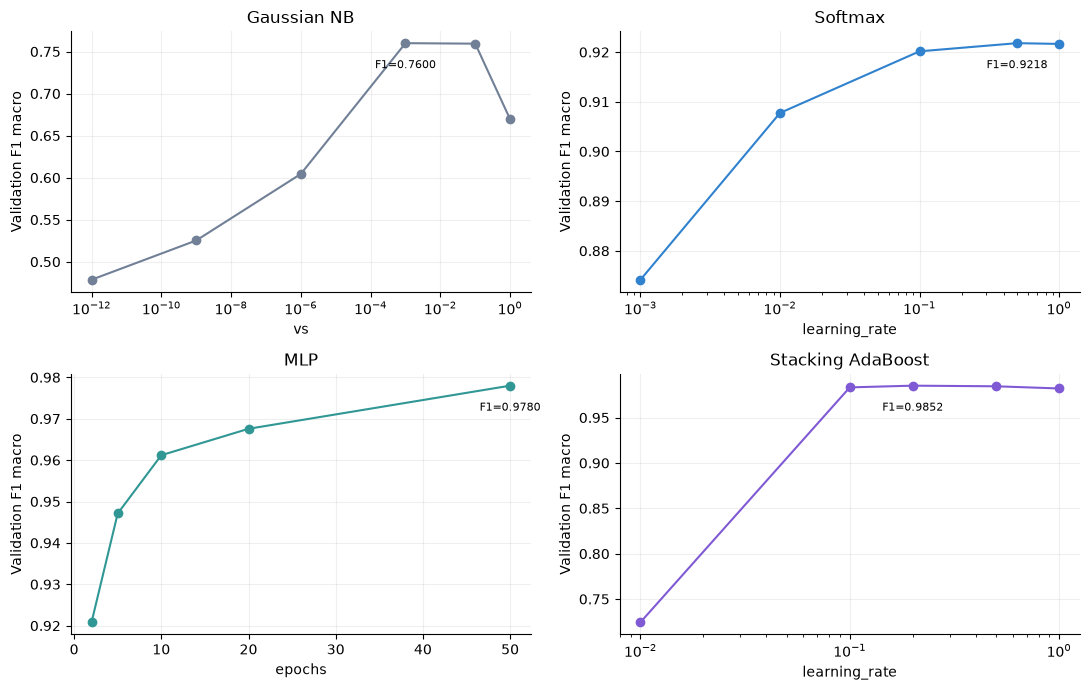

In [24]:
survey_specs = [('Gaussian NB', 'smoothing_search.csv', 'vs', 'model', 'manual', True), ('Softmax', 'learning_rate.csv', 'learning_rate', None, None, True), ('MLP', 'epochs_search.csv', 'epochs', 'model', 'manual', False), ('Stacking AdaBoost', 'hyperparameters.csv', 'learning_rate', None, None, True)]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
survey_rows = []
for ax, (name, filename, parameter, filter_col, filter_value, logx) in zip(axes.flat, survey_specs):
    data = pd.read_csv(ROOT / 'results' / specs[name][0] / filename)
    if filter_col:
        data = data.loc[data[filter_col] == filter_value]
    if name == 'Stacking AdaBoost':
        data = data.loc[(data.max_depth == 2) & (data.n_estimators == 100)]
    data = data.sort_values(parameter)
    ax.plot(data[parameter], data.f1_macro, 'o-', color=COLORS[name])
    if logx:
        ax.set_xscale('log')
    ax.set(title=name, xlabel=parameter, ylabel='Validation F1 macro')
    ax.grid(alpha=0.2)
    for _, row in data.iterrows():
        survey_rows.append(dict(method=name, parameter=parameter, value=row[parameter], validation_f1=row.f1_macro))
    best_row = data.loc[data.f1_macro.idxmax()]
    ax.annotate(f'F1={best_row.f1_macro:.4f}', (best_row[parameter], best_row.f1_macro), xytext=(0, -18), textcoords='offset points', ha='center', fontsize=8)
savefig('hyperparameter_effects.png')
survey_summary = pd.DataFrame(survey_rows)
tables['hyperparameter_effects'] = survey_summary

**Nhận xét:** thay đổi siêu tham số có thể tạo khác biệt lớn, đặc biệt smoothing của Gaussian và learning rate của meta-model. Mỗi đường giữ các điều kiện theo notebook nguồn; không so trực tiếp giá trị tham số giữa các họ mô hình. Giá trị tốt nhất của một sweep không nhất thiết là cấu hình cuối đang báo cáo, ví dụ Gaussian giữ cấu hình cuối đã chốt trước đó.

## 10. Đóng góp thực tế của ensemble
**Mục tiêu:** tách lợi ích của bộ ba với lợi ích riêng của AdaBoost. Mốc model đơn chọn trên validation trong bộ ba đã chọn ở 05, không lấy model có test cao nhất. Weighted voting có thể trùng soft voting nếu trọng số tối ưu bằng nhau.

,method,models,accuracy,f1_macro,fit_seconds,predict_seconds,gain_pp,extra_correct
0,Model đơn tốt nhất,SVM,0.9833,0.983213,965.765842,53.353964,0.00,0
1,Cặp tốt nhất,SVM + MLP256_128,0.9838,0.983705,1307.219412,53.404081,0.05,5
2,Bộ ba tốt nhất,SVM + KNN + MLP256_128,0.9852,0.985146,1307.250312,61.849853,0.19,19


,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
model,,,,,,
SVM,0.9833,0.98333,0.98318,0.98325,942.40321,47.08624
KNN,0.9700,0.97024,0.96962,0.96983,0.03381,3.45399
MLP256_128,0.9826,0.98259,0.98247,0.98252,474.68422,0.08657
Soft voting,0.9852,0.98524,0.98510,0.98516,1417.12124,50.62710
Weighted soft voting,0.9852,0.98524,0.98510,0.98516,1417.12124,50.62761
Stacking AdaBoost,0.9854,0.98540,0.98534,0.98536,6513.24132,50.71464


split,Validation,Test
model,,
SVM,0.9833,0.9833
KNN,0.9720,0.9700
MLP256_128,0.9819,0.9826
Soft voting,0.9852,0.9852
Weighted soft voting,0.9852,0.9852
Stacking AdaBoost,0.9853,0.9854


,reference,corrected_errors,introduced_errors,net_errors_reduced
0,SVM,40,19,21
1,Soft voting,20,18,2


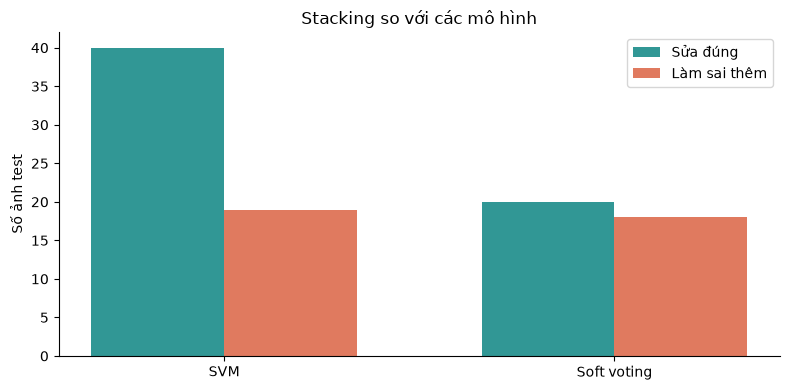

In [25]:
selection_dir = ROOT / 'results' / 'select_base_models'
selection_comparison = pd.read_csv(selection_dir / 'single_pair_triple_comparison.csv')
display(selection_comparison)
tables['base_selection_validation'] = selection_comparison
base_names = e['model_order']
stack_raw = raw['Stacking AdaBoost']
best_base = e['best_single_model']
ensemble_names = base_names + ['Soft voting', 'Weighted soft voting', 'Stacking AdaBoost']
ensemble = stack_raw.loc[stack_raw.model.isin(ensemble_names)].copy()
ensemble_test = ensemble.loc[ensemble.split == 'Test'].set_index('model').loc[ensemble_names]
display(ensemble_test[METRICS + ['fit_seconds', 'predict_seconds']].round(5))
ensemble_scores = ensemble.pivot(index='model', columns='split', values='accuracy').loc[ensemble_names, ['Validation', 'Test']]
display(ensemble_scores.round(5))
error_comparison = pd.read_csv(ROOT / 'results' / 'stacking_adaboost' / 'error_analysis_test.csv')
display(error_comparison)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(error_comparison))
width = 0.34
ax.bar(x - width / 2, error_comparison.corrected_errors, width, label='Sửa đúng', color='#319795')
ax.bar(x + width / 2, error_comparison.introduced_errors, width, label='Làm sai thêm', color='#e07a5f')
ax.set(xticks=x, xticklabels=error_comparison.reference, ylabel='Số ảnh test', title='Stacking so với các mô hình')
ax.legend()
savefig('stacking_error_tradeoff.png')
tables.update(ensemble_test=ensemble_test.reset_index(), ensemble_scores=ensemble_scores.reset_index(), stacking_error_analysis_test=error_comparison)

**Stacking so với SVM:** accuracy chênh +0.21 điểm phần trăm; sửa đúng 40, làm sai thêm 19, giảm ròng 21 lỗi. Fit ghi nhận 6.91 lần, dự đoán 1.08 lần so với mốc. Chênh lệch test chỉ mô tả lượt chạy này, chưa chứng minh khác biệt có ý nghĩa thống kê.

**Stacking so với Soft voting:** accuracy chênh +0.02 điểm phần trăm; sửa đúng 20, làm sai thêm 18, giảm ròng 2 lỗi. Fit ghi nhận 4.60 lần, dự đoán 1.00 lần so với mốc. Chênh lệch test chỉ mô tả lượt chạy này, chưa chứng minh khác biệt có ý nghĩa thống kê.

**Mốc tham chiếu:** SVM được chọn trên validation của bộ ba. Bảng lỗi lấy từ 06 và đã kiểm tra tính nhất quán với số lỗi/accuracy; 06 chưa lưu dự đoán stacking theo từng ảnh nên chưa tái dựng độc lập được danh sách ảnh sửa đúng/làm sai. Soft voting và weighted voting không phải hai nguồn bằng chứng độc lập nếu cùng trọng số.

## 11. Phần mở rộng: CNN, MLP và augmentation
**Mục tiêu:** tách so sánh kiến trúc có ngân sách gần nhau ở 08 khỏi thí nghiệm augmentation 15 epoch ở 09. Không dùng CNN snapshot cũ không có notebook/checkpoint nguồn trong dự án. CNN/augmentation không thay thế bốn phương pháp chính.

,model,accuracy,precision_macro,recall_macro,f1_macro,errors,parameters,best_epoch,fit_seconds
2,MLP260,0.9757,0.97560,0.97551,0.97554,243,206710,50,55.81281
5,CNN_FC128,0.9870,0.98695,0.98702,0.98696,130,206922,19,332.49426


mode,none,all,augmentation_gain_pp
model,,,
CNN_FC128,0.9857,0.9824,-0.33
MLP260,0.9598,0.8763,-8.35


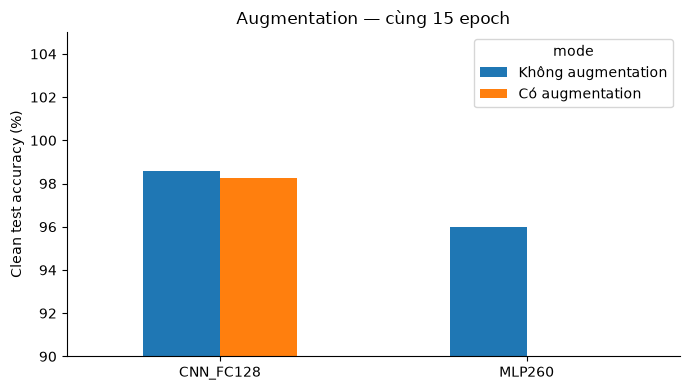

In [26]:
cnn_path = ROOT / 'results' / 'cnn_mlp' / 'metrics.csv'
aug_path = ROOT / 'results' / 'cnn_mlp_augmentation' / 'metrics.csv'
cnn = pd.read_csv(cnn_path)
cnn_test = cnn.loc[cnn.split == 'Test', ['model', *METRICS, 'errors', 'parameters', 'best_epoch', 'fit_seconds']]
display(cnn_test.round(5))
tables['cnn_mlp_test'] = cnn_test
aug = pd.read_csv(aug_path)
aug_cfg = json.loads((aug_path.parent / 'config.json').read_text(encoding='utf-8'))
aug_test = aug.loc[aug.split == 'Test'].copy()
effect = aug_test.pivot(index='model', columns='mode', values='accuracy').loc[:, ['none', 'all']]
effect['augmentation_gain_pp'] = 100 * (effect['all'] - effect['none'])
display(effect.round(5))
tables.update(augmentation_test=aug_test, augmentation_effect=effect.reset_index())
fig, ax = plt.subplots(figsize=(7, 4))
effect[['none', 'all']].rename(columns={'none': 'Không augmentation', 'all': 'Có augmentation'}).mul(100).plot.bar(ax=ax, rot=0)
ax.set(xlabel='', ylabel='Clean test accuracy (%)', ylim=(90, 105), title=f"Augmentation — cùng {aug_cfg['epochs']} epoch")
savefig('augmentation_effect.png')

**Thí nghiệm 08:** với 50 epoch, CNN_FC128 có 206,922 tham số, MLP260 có 206,710; CNN tăng 1.13 điểm phần trăm test accuracy. Số tham số gần nhau hỗ trợ so sánh kiến trúc nhưng không đồng nghĩa số phép tính hoặc thời gian bằng nhau.

**Thí nghiệm 09:** CNN_FC128: thay đổi -0.33 điểm phần trăm; MLP260: thay đổi -8.35 điểm phần trăm. Đây là clean test của cấu hình xoay/dịch/nhiễu đang dùng; không suy rộng thành augmentation luôn tốt hoặc luôn xấu. Đọc thêm phép đo ảnh biến đổi bên dưới trước khi kết luận robustness. Không ghép trực tiếp với bảng 50 epoch của 08.

### 11.1. Độ bền với ảnh bị dịch và xoay
**Mục tiêu:** phân biệt clean accuracy và độ bền dưới biến đổi đã khảo sát. Mức 0 là clean test của cùng mô hình/mode. Không lấy các mức biến đổi test để chọn lại cấu hình; không diễn giải chúng là robustness với mọi loại nhiễu.

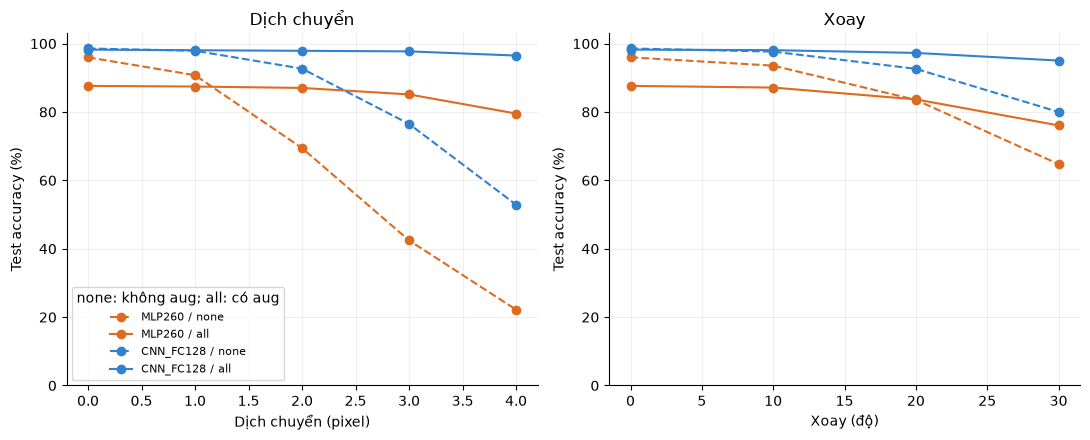

mode,model,kind,level,all,none,augmentation_gain_pp
3,CNN_FC128,rotation,30,0.9504,0.8000,15.04
8,CNN_FC128,shift,4,0.9650,0.5288,43.62
12,MLP260,rotation,30,0.7607,0.6475,11.32
17,MLP260,shift,4,0.7954,0.2218,57.36


In [27]:
robust_path = ROOT / 'results' / 'cnn_mlp_augmentation' / 'robustness.csv'
robust = pd.read_csv(robust_path)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, kind, label in zip(axes, ['shift', 'rotation'], ['Dịch chuyển (pixel)', 'Xoay (độ)']):
    data = robust.loc[robust.kind == kind]
    for (model, mode), group in data.groupby(['model', 'mode'], sort=False):
        group = group.sort_values('level')
        ax.plot(group.level, group.accuracy * 100, marker='o', linestyle='-' if mode == 'all' else '--', color='#3182ce' if model == 'CNN_FC128' else '#dd6b20', label=f'{model} / {mode}')
    ax.set(xlabel=label, ylabel='Test accuracy (%)', title=label.split(' (')[0], ylim=(0, 103))
    ax.grid(alpha=0.2)
axes[0].legend(title='none: không aug; all: có aug', loc='lower left', fontsize=8)
savefig('robustness_comparison.png')
robust_wide = robust.pivot(index=['model', 'kind', 'level'], columns='mode', values='accuracy').reset_index()
robust_wide['augmentation_gain_pp'] = 100 * (robust_wide['all'] - robust_wide['none'])
strongest = robust_wide.loc[robust_wide.level == robust_wide.groupby(['model', 'kind'])['level'].transform('max')]
display(strongest.round(4))
tables.update(robustness=robust, robustness_augmentation_gains=robust_wide)

**Robustness tại mức biến đổi lớn nhất đã đo:** CNN_FC128, rotation=30: augmentation chênh +15.04 điểm phần trăm; CNN_FC128, shift=4: augmentation chênh +43.62 điểm phần trăm; MLP260, rotation=30: augmentation chênh +11.32 điểm phần trăm; MLP260, shift=4: augmentation chênh +57.36 điểm phần trăm. Đọc cùng clean accuracy ở mức 0: giảm điểm clean và tăng điểm trên ảnh biến đổi có thể cùng xảy ra. Các số liệu chỉ áp dụng cho phép biến đổi và mức độ trong thí nghiệm 09.

## 12. Ưu/nhược điểm, khả năng giải thích và kết luận
**Mục tiêu:** kết hợp bằng chứng định lượng với đặc điểm phương pháp, không gắn nhãn “tốt nhất” cho mọi tiêu chí. Phần khả năng giải thích dưới đây là phân tích định tính, chưa có đánh giá bằng SHAP/LIME hay nghiên cứu người dùng.

| Phương pháp | Ưu điểm | Hạn chế | Khả năng giải thích |
|---|---|---|---|
| Gaussian NB | Fit bằng thống kê theo lớp; tham số có ý nghĩa xác suất | Giả định độc lập có điều kiện/Gaussian hạn chế mô tả ảnh | Có thể xem prior, mean, variance; 784 pixel vẫn khó giải thích từng quyết định |
| Softmax | Mô hình gọn; logit tuyến tính, trực quan được bản đồ trọng số | Không biểu diễn trực tiếp tương tác phi tuyến giữa pixel | Đóng góp tuyến tính theo lớp; trọng số không phải bằng chứng nhân quả |
| MLP | Học tương tác phi tuyến; suy luận bằng chuỗi nhân ma trận | Phụ thuộc tối ưu, kiến trúc và regularization; có thể khớp train quá mức | Biểu diễn ẩn khó diễn giải trực tiếp hơn mô hình tuyến tính |
| Stacking AdaBoost | Kết hợp dự đoán của nhiều họ mô hình bằng đặc trưng OOF | Fit OOF/refit tốn chi phí; tăng test nhỏ chưa đủ chứng minh ưu thế ổn định | Cần giải thích cả base models và meta-model; importance của meta không giải thích trực tiếp pixel |

**Kết luận cho báo cáo:** bốn pipeline có sự đánh đổi giữa chất lượng, chi phí và mức độ giải thích. Gaussian NB đạt 77.53%, Softmax 92.53%, MLP tự viết 98.19%, stacking 98.54% test accuracy. Bảng lỗi ghép cặp cho biết lợi ích và thiệt hại trên dự đoán, thay vì chỉ nhìn accuracy tổng. Khi lựa chọn cho ứng dụng, dùng validation và ràng buộc thời gian đã xác định trước, không chọn lại bằng test. Hạn chế: một seed, tuning khác ngân sách, thời gian chưa đo lặp trong môi trường thống nhất và thiếu ID ảnh ở một số đầu ra. Các nhận định nguyên nhân như độc lập pixel, khác phân phối OOF/refit hay augmentation quá mạnh là giả thuyết cần thí nghiệm kiểm chứng.

## 13. Xuất kết quả và nhận xét cho báo cáo
**Mục tiêu:** lưu các bảng được tính trong lần chạy hiện tại, hình 300 dpi, nhận xét và danh sách đầu ra. Manifest chỉ liệt kê đầu ra hiện tại; các file cũ ngoài manifest trong cùng thư mục không tự trở thành kết quả hợp lệ. Chạy lại ghi đè các file cùng tên.

In [28]:
for name, table in tables.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False, encoding='utf-8-sig')
summary = {'methods': METHODS, 'splits': SPLITS, 'seed': 42, 'output_tables': [f'{name}.csv' for name in tables], 'output_figures': figures}
(OUTPUT / 'comparison_config.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Đã lưu {len(tables)} bảng và {len(figures)} hình tại {OUTPUT}')

Đã lưu 22 bảng và 9 hình tại d:\mnist\results\comparison
